In [1]:
import pandas as pd
import numpy as nu
from matplotlib import pyplot as plt

In [2]:
# Load and copy suya orders data.

suya_df = pd.read_csv('data/suya_orders.csv').copy()

In [3]:
# inspect the dataset

suya_df.head(2)

,Order_ID,Date,Branch,Item,Quantity,Unit_Price_NGN,Total_NGN,Payment_Method,Customer_Age,Rating,Is_Delivery
0,SP101081,2025-08-03,Port Harcourt GRA,Ram Suya,1,2700,2700,Cash,27.0,4.0,No
1,SP102241,2025-03-14,Lagos Yaba,Chicken Suya,6,2050,12300,Cash,41.0,5.0,No


In [4]:
suya_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order_ID        5000 non-null   object 
 1   Date            5000 non-null   object 
 2   Branch          5000 non-null   object 
 3   Item            5000 non-null   object 
 4   Quantity        5000 non-null   int64  
 5   Unit_Price_NGN  5000 non-null   int64  
 6   Total_NGN       5000 non-null   int64  
 7   Payment_Method  4847 non-null   object 
 8   Customer_Age    4719 non-null   float64
 9   Rating          4604 non-null   float64
 10  Is_Delivery     5000 non-null   object 
dtypes: float64(2), int64(3), object(6)
memory usage: 429.8+ KB


In [5]:
suya_df.isnull().sum()

Order_ID            0
Date                0
Branch              0
Item                0
Quantity            0
Unit_Price_NGN      0
Total_NGN           0
Payment_Method    153
Customer_Age      281
Rating            396
Is_Delivery         0
dtype: int64

In [6]:
suya_df.describe()

,Quantity,Unit_Price_NGN,Total_NGN,Customer_Age,Rating
count,5000.000000,5000.000000,5000.000000,4719.000000,4604.000000
mean,2.562200,1739.880000,4538.160000,29.253867,4.041268
std,4.432433,533.998705,9530.478415,7.811225,0.779400
min,1.000000,500.000000,500.000000,14.000000,2.000000
25%,1.000000,1500.000000,1800.000000,24.000000,4.000000
50%,2.000000,1800.000000,3300.000000,29.000000,4.000000
75%,3.000000,2000.000000,5400.000000,35.000000,5.000000
max,109.000000,2900.000000,272500.000000,62.000000,5.000000


In [7]:
# Convert date to datetime object

suya_df['Date'] = pd.to_datetime(suya_df['Date'])

# Which branch makes the most money? Which makes the least?

In [8]:
# Verify there is no mispellet and repeated branch

suya_df['Branch'].value_counts()

Branch
Lagos Yaba           915
Abuja Wuse           835
Kaduna Central       801
Kano Sabon Gari      679
Port Harcourt GRA    507
Ibadan Bodija        444
Enugu Ogui           416
Jos Terminus         403
Name: count, dtype: int64

In [9]:
# Group by branch

branch = suya_df.groupby(by='Branch')['Total_NGN'].sum().sort_values()

# Branch that make most money
print(branch.nlargest(1))

# Branch that make most money
print(branch.nsmallest(1))

Branch
Lagos Yaba    5204600
Name: Total_NGN, dtype: int64
Branch
Enugu Ogui    1647200
Name: Total_NGN, dtype: int64


# Branch that make most money
    Lagos Yaba
# Branch that makes the least money
    Enugu Ogui

In [10]:
# Most popular item

suya_df.groupby(by='Item')['Quantity'].sum().nlargest(1)

Item
Beef Suya    3629
Name: Quantity, dtype: int64

In [11]:
# Item that makes most money
item = suya_df.groupby(by='Item')['Total_NGN'].sum()
item.nlargest(1)

Item
Chicken Suya    6347550
Name: Total_NGN, dtype: int64

Beef suya is the most popular

Chicken suya makes the most money

In [12]:
# month with the highest sales

suya_df['Month'] = suya_df['Date'].dt.month_name()

In [13]:
month = suya_df.groupby(by='Month')['Total_NGN'].sum()

# Month with highest sales
print(month.nlargest(1))

# Month with the lowest sales
print(month.nsmallest(1))

Month
July    2152850
Name: Total_NGN, dtype: int64
Month
February    1585200
Name: Total_NGN, dtype: int64


Highest sales in July

Lowest Sales in February

In [14]:
# Payment method used most by customers

suya_df['Payment_Method'].value_counts().nlargest(1)

Payment_Method
Cash    1931
Name: count, dtype: int64

Cash is the payment method used most

In [15]:
# Do delivery orders get lower ratings than other orders?

suya_df.groupby(by='Is_Delivery')['Rating'].mean()

Is_Delivery
No     4.146917
Yes    3.771605
Name: Rating, dtype: float64

Yes, delivery orders get lower ratings than other orders

In [16]:
# Average age of customers

suya_df['Customer_Age'].mean()

np.float64(29.253867344776435)

In [17]:
# age ranges
age_group = [0, 17, 24, 34, 44, 100]

# Give each age range a meaningful label
age_group_labels = [
    "Under 18",
    "18-24",
    "25-34",
    "35-44",
    "45+"
]

# Create an Age_Group column
suya_df["Age_Group"] = pd.cut(
    suya_df["Customer_Age"],
    bins=age_group,
    labels=age_group_labels
)

# Count customers in each age group
age_group_counts = suya_df["Age_Group"].value_counts().sort_values(ascending=False)

age_group_counts

Age_Group
25-34       2207
35-44       1065
18-24        963
Under 18     358
45+          126
Name: count, dtype: int64

Mean Age = 29.3

Age group that buys most = 25 to 34

In [18]:
# Busiest day

suya_df['Day'] = suya_df['Date'].dt.day_name()

suya_df['Day'].value_counts().sort_values(ascending=False)

Day
Wednesday    757
Saturday     751
Tuesday      741
Friday       718
Monday       688
Sunday       675
Thursday     670
Name: count, dtype: int64

Wednesday is the most busiest day of the week

In [19]:
# Do bigger orders (higher Quantity) get better ratings?

rating_vs_quantity = suya_df[["Quantity", "Rating"]].dropna()

correlation = rating_vs_quantity["Quantity"].corr(
    rating_vs_quantity["Rating"]
)

print(f"Correlation between Quantity and Rating: {correlation:.2f}")

Correlation between Quantity and Rating: -0.01


-0.01 correlation is insignificant because it is close to 0

In [20]:
# Branch with happiest customers

suya_df.groupby("Branch")["Rating"].mean().nlargest(1)

Branch
Ibadan Bodija    4.081146
Name: Rating, dtype: float64

Ibadan branch have the happiest customer

### 1. Increase sales at weaker branches

Lagos Yaba generates the highest revenue, while Enugu Ogui generates the lowest revenue. I would investigate what Lagos Yaba is doing differently and apply successful strategies to weaker branches, such as better promotion, product combinations, or targeted advertising.

### 2. Promote Beef Suya and other high-performing products

Beef Suya is the most popular product, and chicken suya is highest-revenue product. I would make Beef Suya and chiken suya a major part of promotions and consider combo deals that include Beef Suya with drinks or other products to increase the value of each order.

### 3. Improve the delivery experience

Delivery orders have an average rating of 3.77 compared with 4.15 for non-delivery orders. I would investigate delivery times, packaging, food temperature, and delivery staff performance. Improving the delivery experience could increase customer satisfaction and encourage more customers to order through delivery.

# Week 2

### Monday: Variables, Data Types, Operators, Input/Output, Type Conversion
1. Store a suya spot's name, the price of one portion, and the number of portions sold in three variables. Print one sentence using all three.

In [21]:
# Store the name of the suya spot
suya_spot = "Legend Suya Spot"

# Store the price of one portion
price_per_portion = 2000

# Store the number of portions sold
portions_sold = 5

# Print all three values in one sentence
print(
    f"{suya_spot} sold {portions_sold} portions "
    f"at ₦{price_per_portion} per portion."
)

Legend Suya Spot sold 5 portions at ₦2000 per portion.


2. Use `input()` to ask for a price and a quantity. Print the total.

In [22]:
# enter the price
price = input("Enter the price of one portion: ")

# enter the quantity
quantity = input("Enter the number of portions: ")

# Convert the inputs from text to numbers
price = float(price)
quantity = int(quantity)

# Calculate the total
total = price * quantity

# Print the total
print(f"Total: ₦{total}")

Enter the price of one portion:  23
Enter the number of portions:  4


Total: ₦92.0


3. Convert the text `"1500"` to a number and add 250 to it.

In [23]:
price_text = "1500"

# Convert the text to an integer
price_number = int(price_text)

new_price = price_number + 250

print(new_price)

1750


### Wednesday: Strings, Lists, Tuples, Dictionaries, Sets
1. Take the text `"  beef suya  "`. Remove the spaces and print it in capital letters.

In [24]:
item = "  beef suya  "

# Remove spaces from the beginning and end
item = item.strip()
item = item.upper()
print(item)

BEEF SUYA


2. Make a list of 5 menu items. Add one more item and print the list.

In [25]:
menu_items = [
    "Beef Suya",
    "Chicken Suya",
    "Ram Suya",
    "Kilishi",
    "Gizzard"
]
# Add fish Suya
menu_items.append("Fish Suya")
print(menu_items)

['Beef Suya', 'Chicken Suya', 'Ram Suya', 'Kilishi', 'Gizzard', 'Fish Suya']


3. Make a dictionary of 3 menu items and their prices. Print the price of one item.

In [26]:
menu_prices = {
    "Beef Suya": 1500,
    "Chicken Suya": 2000,
    "Ram Suya": 2500
}

# Print the price of Beef Suya
print(menu_prices["Beef Suya"])

1500


4. Turn the list `["Cash", "POS", "Cash", "Transfer"]` into a set.

In [27]:
payment_methods = ["Cash", "POS", "Cash", "Transfer"]

# Convert the list to a set
unique_payment_methods = set(payment_methods)
print(unique_payment_methods)

{'POS', 'Cash', 'Transfer'}


5. Make a dictionary of menu prices. Make a list of items a customer bought. Print the total bill.

In [28]:
menu_prices = {
    "Beef Suya": 1500,
    "Chicken Suya": 2000,
    "Kilishi": 2000,
    "Ram Suya": 2500
}

items_bought = [
    "Beef Suya",
    "Beef Suya",
    "Chicken Suya",
    "Kilishi"
]

total_bill = 0


for item in items_bought:
    # Find the item's price in the dictionary
    price = menu_prices[item]
    # Add the price to the total bill
    total_bill = total_bill + price

print(f"Total bill: ₦{total_bill}")

Total bill: ₦7000


## Week 3: Programming with Python

### Monday: Loops, Conditionals, Functions
1. Use a `for` loop to print the numbers 1 to 10.

In [112]:
for number in range(1, 11):
    print(number)

1
2
3
4
5
6
7
8
9
10


2. Write an `if/else` that prints "Big order" if a total is above 5,000, otherwise "Small order".

In [113]:
total = 6500

if total > 5000:
    print("Big order")
else:
    print("Small order")

Big order


3. Write a function `add_vat(price)` that adds 7.5% to a price and returns it. Test it.

In [114]:
def add_vat(price):
    vat = price * 0.075
    final_price = price + vat
    return final_price


# Test the function
price = 5000

result = add_vat(price)

print("Price:", price)
print("Price with VAT:", result)

Price: 5000
Price with VAT: 5375.0


### Wednesday: Exception Handling, Modules, File Handling, Documentation
1. Ask the user for a number. Use `try/except` so the program does not crash if they type words.

In [115]:
try:
    number = float(input("Enter a number: "))
    print("You entered:", number)

except ValueError:
    print("Invalid input. Please enter a number.")

Enter a number:  4


You entered: 4.0


2. Import `random` and pick one random item from a list of menu items.

In [116]:
import random

menu_items = [
    "Beef Suya",
    "Chicken Suya",
    "Ram Suya",
    "Kilishi",
    "Gizzard"
]

random_item = random.choice(menu_items)

print("Today's random menu item:", random_item)

Today's random menu item: Ram Suya


3. Write 3 menu items into a text file, then read the file and print it.

In [117]:
# Create and write to the file
with open("suya_menu.txt", "w") as menu_file:
    menu_file.write("Beef Suya\n")
    menu_file.write("Chicken Suya\n")
    menu_file.write("Kilishi\n")


# Read the file
with open("suya_menu.txt", "r") as menu_file:
    menu = menu_file.read()

print(menu)

Beef Suya
Chicken Suya
Kilishi



## Week 4: Working with Data

### Monday: NumPy Arrays, Vectorization, Broadcasting
1. Make a NumPy array of 6 suya prices. Print the mean, max and min.

In [29]:
import numpy as np

suya_prices = np.array([1500, 1800, 2000, 2200, 2500, 3000])

print("Mean:", suya_prices.mean())
print("Maximum:", suya_prices.max())
print("Minimum:", suya_prices.min())

Mean: 2166.6666666666665
Maximum: 3000
Minimum: 1500


2. Increase every price by 10% without using a loop.

In [30]:
increased_prices = suya_prices * 1.10

print(increased_prices)

[1650. 1980. 2200. 2420. 2750. 3300.]


3. Add 200 to every price in the array.

In [31]:
new_prices = suya_prices + 200

print(new_prices)

[1700 2000 2200 2400 2700 3200]


### Wednesday: Pandas Series and DataFrames, Importing CSV
1. Load `suya_orders.csv`. Print `shape`, `head()` and `info()`.

In [32]:
import pandas as pd

orders = pd.read_csv("data/suya_orders.csv")

print("Shape:")
print(orders.shape)

print("\nFirst 5 rows:")
print(orders.head())

print("\nData information:")
print(orders.info())

Shape:
(5000, 11)

First 5 rows:
   Order_ID        Date             Branch          Item  Quantity  \
0  SP101081  2025-08-03  Port Harcourt GRA      Ram Suya         1   
1  SP102241  2025-03-14         Lagos Yaba  Chicken Suya         6   
2  SP102723  2025-11-11         Enugu Ogui     Beef Suya         5   
3  SP101028  2025-03-09         Enugu Ogui       Kilishi         1   
4  SP100619  2025-09-07    Kano Sabon Gari     Beef Suya         3   

   Unit_Price_NGN  Total_NGN Payment_Method  Customer_Age  Rating Is_Delivery  
0            2700       2700           Cash          27.0     4.0          No  
1            2050      12300           Cash          41.0     5.0          No  
2            1500       7500           Cash          31.0     5.0          No  
3            2000       2000            POS          22.0     4.0          No  
4            1500       4500           Cash          20.0     5.0          No  

Data information:
<class 'pandas.core.frame.DataFrame'>
RangeInde

2. Print the `Item` column.

In [33]:
# 2. Print the Item column

print(orders["Item"])

0           Ram Suya
1       Chicken Suya
2          Beef Suya
3            Kilishi
4          Beef Suya
            ...     
4995         Kilishi
4996      Soft Drink
4997        Ram Suya
4998    Chicken Suya
4999         Kilishi
Name: Item, Length: 5000, dtype: object


3. Show only the orders from "Kaduna Central". How many are there?

In [34]:
# 3. Show only orders from Kaduna Central
# Count how many orders there are

kaduna_orders = orders[orders["Branch"] == "Kaduna Central"]

print(kaduna_orders)
print("\nNumber of Kaduna Central orders:", len(kaduna_orders))

      Order_ID        Date          Branch          Item  Quantity  \
6     SP102778  2025-10-08  Kaduna Central     Beef Suya         1   
10    SP102146  2025-09-17  Kaduna Central  Chicken Suya         1   
11    SP102643  2025-09-13  Kaduna Central      Ram Suya         2   
23    SP102436  2025-07-23  Kaduna Central       Kilishi         2   
24    SP100805  2025-09-17  Kaduna Central     Beef Suya         3   
...        ...         ...             ...           ...       ...   
4954  SP100842  2025-06-25  Kaduna Central    Soft Drink         4   
4960  SP104530  2025-11-05  Kaduna Central      Ram Suya         1   
4984  SP103259  2025-07-24  Kaduna Central       Kilishi         2   
4995  SP101149  2025-12-20  Kaduna Central       Kilishi         3   
4999  SP100382  2025-06-20  Kaduna Central       Kilishi         2   

      Unit_Price_NGN  Total_NGN Payment_Method  Customer_Age  Rating  \
6               1500       1500           Cash          31.0     5.0   
10             

4. Save the first 100 rows to a new CSV file.

In [35]:
# 4. Save the first 100 rows to a new CSV file

first_100_orders = orders.head(100)

first_100_orders.to_csv(
    "first_100_suya_orders.csv",
    index=False
)

## Week 5: Data Cleaning

### Monday: Missing Values, Duplicate Records, Data Types
1. Make a copy of the data. Count the missing values in each column.

In [36]:
# 1. Make a copy of the data
# Count missing values in each column

clean_orders = orders.copy()

missing_values = clean_orders.isnull().sum()

print(missing_values)

Order_ID            0
Date                0
Branch              0
Item                0
Quantity            0
Unit_Price_NGN      0
Total_NGN           0
Payment_Method    153
Customer_Age      281
Rating            396
Is_Delivery         0
dtype: int64


2. Fill the missing `Customer_Age` with the median. Fill the missing `Payment_Method` with "Unknown".

In [37]:
# 2. Fill missing Customer_Age with the median
# Fill missing Payment_Method with "Unknown"

median_age = clean_orders["Customer_Age"].median()

clean_orders["Customer_Age"] = clean_orders["Customer_Age"].fillna(
    median_age
)

clean_orders["Payment_Method"] = clean_orders["Payment_Method"].fillna(
    "Unknown"
)

print(clean_orders.isnull().sum())

Order_ID            0
Date                0
Branch              0
Item                0
Quantity            0
Unit_Price_NGN      0
Total_NGN           0
Payment_Method      0
Customer_Age        0
Rating            396
Is_Delivery         0
dtype: int64


3. Count the duplicate rows, then remove them.

In [38]:
# 3. Count duplicate rows and then remove them

duplicate_count = clean_orders.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

clean_orders = clean_orders.drop_duplicates()

print("Duplicates remaining:", clean_orders.duplicated().sum())

Number of duplicate rows: 50
Duplicates remaining: 0


4. Convert the `Date` column to a date type.

In [39]:
# 4. Convert Date to a date type

clean_orders["Date"] = pd.to_datetime(clean_orders["Date"])

print(clean_orders["Date"].dtype)

datetime64[ns]


### Wednesday: Outliers, Feature Engineering, Data Transformation
1. Find the 10 biggest orders by `Total_NGN`. Do any look strange?

In [40]:
# 1. Find the 10 biggest orders by Total_NGN

biggest_orders = clean_orders['Total_NGN'].nlargest(10)

print(biggest_orders)

2180    272500
4710    252300
602     225400
2123    196800
1556    180000
1062    178000
2064    170150
2270    157850
60      153000
4025    149400
Name: Total_NGN, dtype: int64


2. Draw a boxplot of `Total_NGN`.

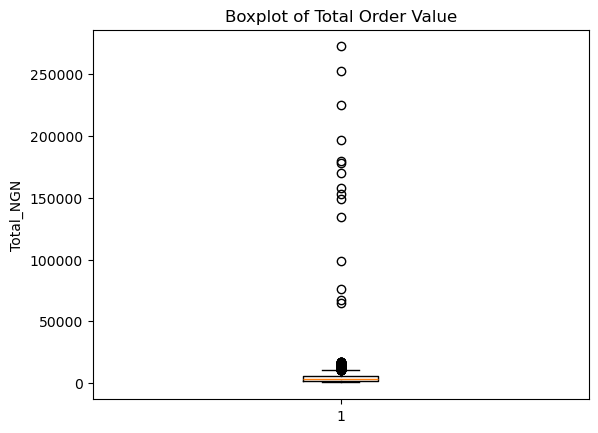

In [41]:
# 2. Draw a boxplot of Total_NGN

import matplotlib.pyplot as plt

plt.boxplot(clean_orders["Total_NGN"].dropna())

plt.title("Boxplot of Total Order Value")
plt.ylabel("Total_NGN")

plt.show()

3. Create a new column called `Month` from `Date`.

In [42]:
# 3. Create a Month column from Date

clean_orders["Month"] = clean_orders["Date"].dt.month_name()

print(clean_orders[["Date", "Month"]].head())

        Date      Month
0 2025-08-03     August
1 2025-03-14      March
2 2025-11-11   November
3 2025-03-09      March
4 2025-09-07  September


4. Change `Is_Delivery` from Yes and No into 1 and 0.


In [43]:
# 4. Change Is_Delivery from Yes/No into 1/0

clean_orders["Is_Delivery"] = clean_orders["Is_Delivery"].map({
    "Yes": 1,
    "No": 0
})

print(clean_orders["Is_Delivery"].value_counts())

Is_Delivery
0    3555
1    1395
Name: count, dtype: int64


## Week 6: Exploratory Data Analysis

### Monday: Summary Statistics, Correlation Analysis
1. Use `describe()` on `Total_NGN`.

In [44]:
# 1. Use describe() on Total_NGN

print(clean_orders["Total_NGN"].describe())

count      4950.000000
mean       4541.141414
std        9572.949583
min         500.000000
25%        1800.000000
50%        3300.000000
75%        5400.000000
max      272500.000000
Name: Total_NGN, dtype: float64


2. Find the average `Total_NGN` for each Branch.

In [45]:
# 2. Find the average Total_NGN for each Branch

average_branch_sales = clean_orders.groupby(
    "Branch"
)["Total_NGN"].mean()

print(average_branch_sales)

Branch
Abuja Wuse           4819.673123
Enugu Ogui           3963.080685
Ibadan Bodija        4207.449210
Jos Terminus         4362.094763
Kaduna Central       4097.458704
Kano Sabon Gari      4246.656761
Lagos Yaba           5702.312775
Port Harcourt GRA    3982.504970
Name: Total_NGN, dtype: float64


3. Find the correlation between `Quantity` and `Total_NGN`.

In [46]:
# 3. Find the correlation between Quantity and Total_NGN

quantity_sales_correlation = clean_orders[
    ["Quantity", "Total_NGN"]
].corr().loc["Quantity", "Total_NGN"]

print(quantity_sales_correlation)

0.9724168404090003


4. Print the mean and the median of `Total_NGN`. Which one is bigger?

In [47]:
# 4. Find the mean and median of Total_NGN
# Which one is bigger?

sales_mean = clean_orders["Total_NGN"].mean()
sales_median = clean_orders["Total_NGN"].median()

print("Mean:", sales_mean)
print("Median:", sales_median)

if sales_mean > sales_median:
    print("The mean is bigger.")
elif sales_median > sales_mean:
    print("The median is bigger.")
else:
    print("The mean and median are equal.")

Mean: 4541.141414141414
Median: 3300.0
The mean is bigger.


5. Count how many orders each Item has.

In [48]:
# 5. Count how many orders each Item has

item_order_counts = clean_orders["Item"].value_counts()

print(item_order_counts)

Item
Beef Suya       1495
Chicken Suya    1142
Kilishi          708
Ram Suya         627
Gizzard          599
Soft Drink       379
Name: count, dtype: int64


6. Find the total `Total_NGN` for each `Payment_Method`.

In [49]:
# 6. Find the total Total_NGN for each Payment_Method

payment_sales = clean_orders.groupby(
    "Payment_Method"
)["Total_NGN"].sum()

print(payment_sales)

Payment_Method
Cash        8507300
POS         5758600
Transfer    7497850
Unknown      714900
Name: Total_NGN, dtype: int64


7. Find the average `Rating` for each Branch.

In [50]:
# 7. Find the average Rating for each Branch

branch_ratings = clean_orders.groupby(
    "Branch"
)["Rating"].mean()

print(branch_ratings)

Branch
Abuja Wuse           4.065160
Enugu Ogui           4.055703
Ibadan Bodija        4.081340
Jos Terminus         4.059140
Kaduna Central       3.976323
Kano Sabon Gari      4.035200
Lagos Yaba           4.055156
Port Harcourt GRA    4.017316
Name: Rating, dtype: float64


8. Find the correlation between `Customer_Age` and `Total_NGN`.

In [51]:
# 8. Find the correlation between Customer_Age and Total_NGN

age_sales_correlation = clean_orders[
    ["Customer_Age", "Total_NGN"]
].corr().loc["Customer_Age", "Total_NGN"]

print(age_sales_correlation)

-0.02358555296121147


9. Find the correlation between `Quantity` and `Rating`.

In [52]:
# 9. Find the correlation between Quantity and Rating

quantity_rating_correlation = clean_orders[
    ["Quantity", "Rating"]
].corr().loc["Quantity", "Rating"]

print(quantity_rating_correlation)

-0.014589439057958571


10. Find the percentage of orders that are deliveries and the percentage that are not.

In [53]:
# 10. Find the percentage of orders that are deliveries
# and the percentage that are not

delivery_percentages = (
    clean_orders["Is_Delivery"]
    .value_counts(normalize=True)
    .mul(100)
)

print(delivery_percentages)

Is_Delivery
0    71.818182
1    28.181818
Name: proportion, dtype: float64


### Wednesday: Matplotlib, Seaborn, Business Insights
1. Draw a bar chart of total sales for each Branch. Add a title.

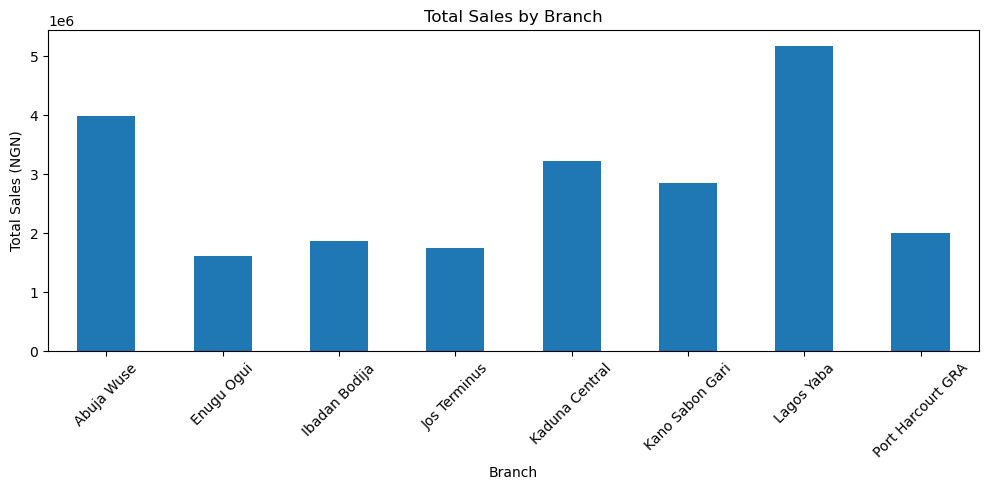

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns


branch_total_sales = clean_orders.groupby(
    "Branch"
)["Total_NGN"].sum()

branch_total_sales.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Total Sales by Branch")
plt.xlabel("Branch")
plt.ylabel("Total Sales (NGN)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

2. Draw a Seaborn boxplot of `Total_NGN` for each Item.

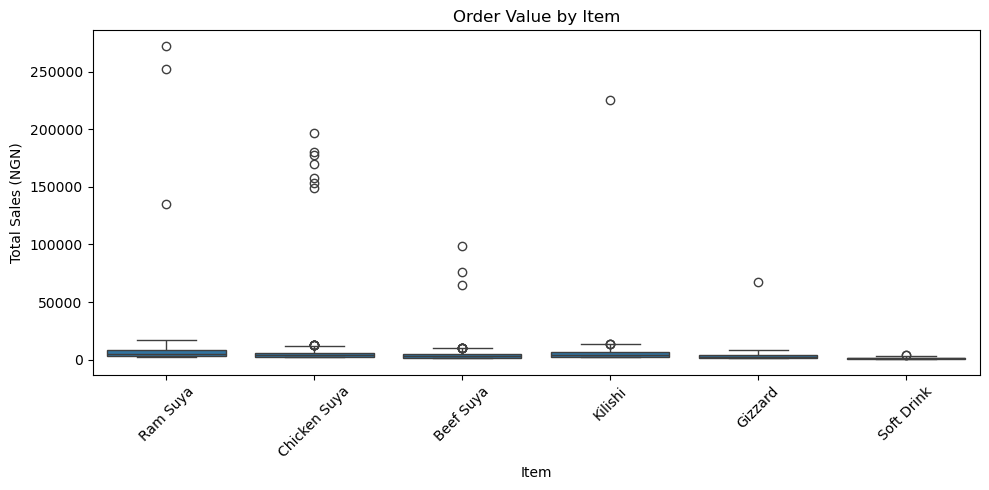

In [55]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=clean_orders,
    x="Item",
    y="Total_NGN"
)

plt.title("Order Value by Item")
plt.xlabel("Item")
plt.ylabel("Total Sales (NGN)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

3. Draw a line chart of total sales for each Month.

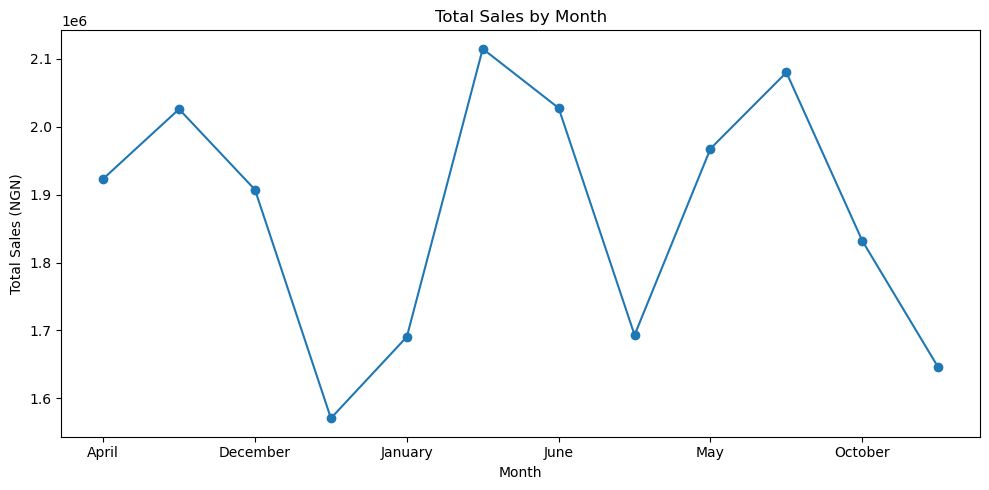

In [56]:
monthly_sales = clean_orders.groupby(
    "Month"
)["Total_NGN"].sum()

monthly_sales.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Total Sales by Month")
plt.xlabel("Month")
plt.ylabel("Total Sales (NGN)")

plt.tight_layout()
plt.show()

4. Draw a bar chart of the number of orders for each Item.

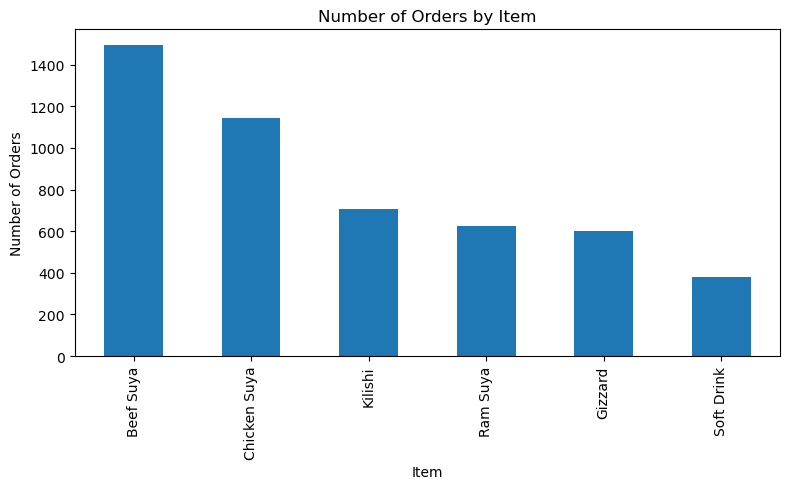

In [57]:
item_order_counts = clean_orders["Item"].value_counts()

item_order_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Number of Orders by Item")
plt.xlabel("Item")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

5. Draw a histogram of `Customer_Age`.

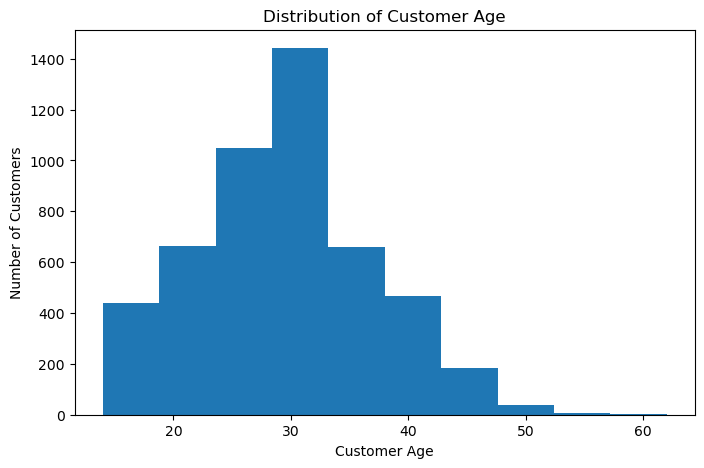

In [58]:
plt.figure(figsize=(8, 5))

plt.hist(
    clean_orders["Customer_Age"].dropna(),
    bins=10
)

plt.title("Distribution of Customer Age")
plt.xlabel("Customer Age")
plt.ylabel("Number of Customers")

plt.show()

6. Draw a bar chart of the average `Rating` for each Branch.

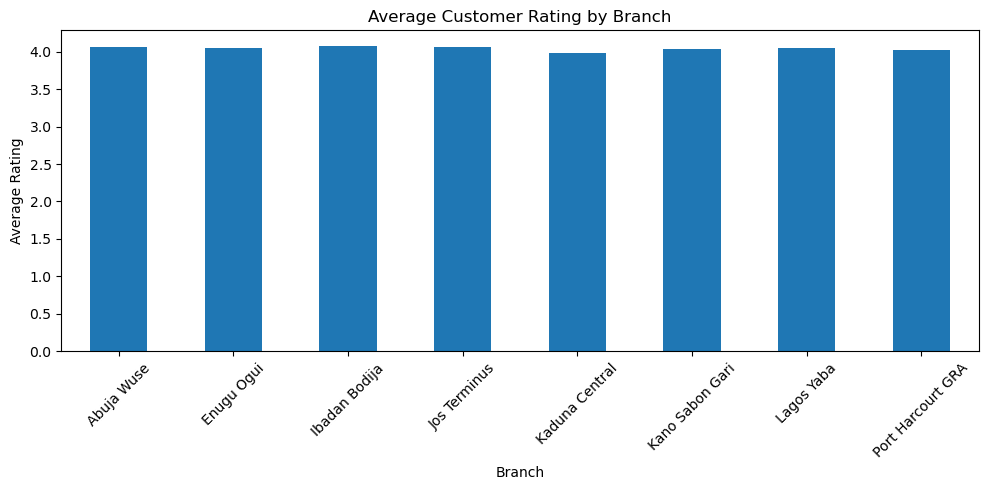

In [59]:
branch_average_rating = clean_orders.groupby(
    "Branch"
)["Rating"].mean()

branch_average_rating.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Customer Rating by Branch")
plt.xlabel("Branch")
plt.ylabel("Average Rating")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

7. Draw a Seaborn countplot of `Payment_Method`.

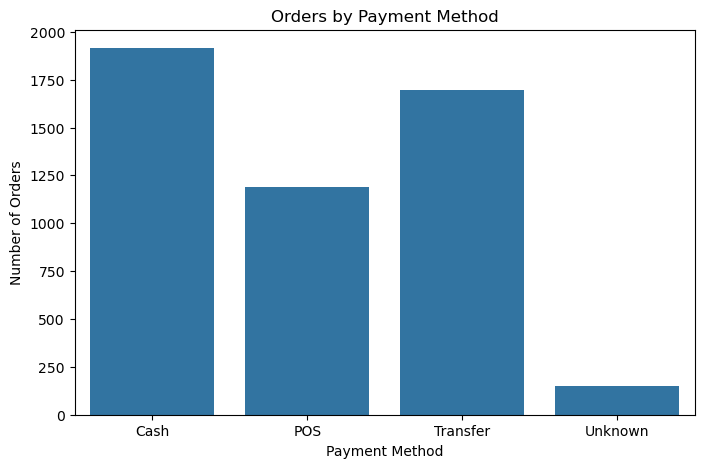

In [60]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=clean_orders,
    x="Payment_Method"
)

plt.title("Orders by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")

plt.show()

8. Draw a scatter plot of `Quantity` against `Total_NGN`.

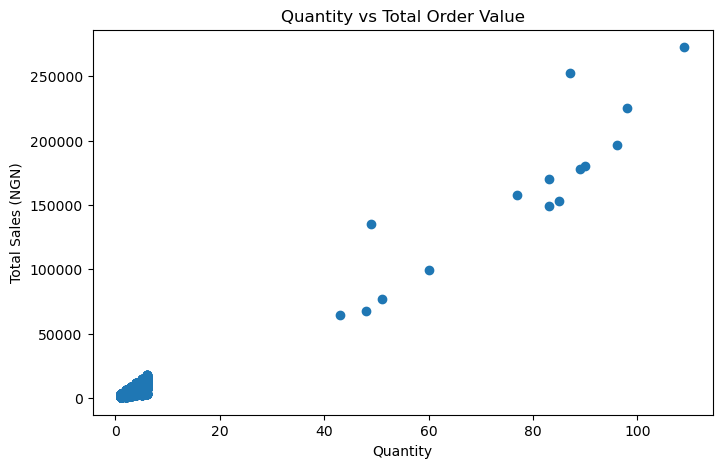

In [61]:
plt.figure(figsize=(8, 5))

plt.scatter(
    clean_orders["Quantity"],
    clean_orders["Total_NGN"]
)

plt.title("Quantity vs Total Order Value")
plt.xlabel("Quantity")
plt.ylabel("Total Sales (NGN)")

plt.show()

9. Draw a correlation heatmap of `Quantity`, `Total_NGN`, `Customer_Age` and `Rating`.

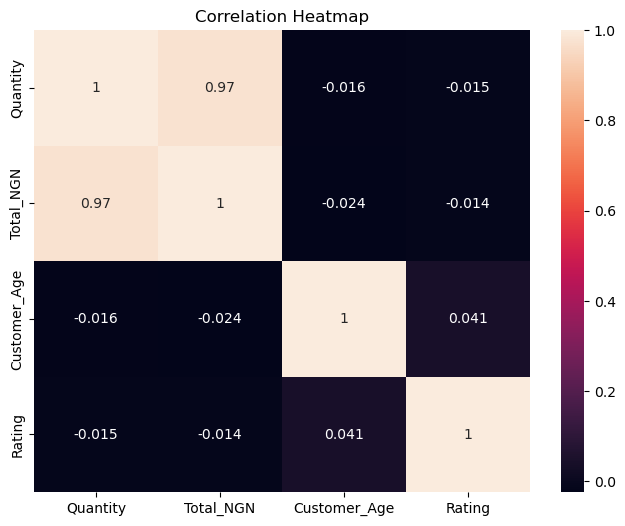

In [62]:
correlation_data = clean_orders[
    [
        "Quantity",
        "Total_NGN",
        "Customer_Age",
        "Rating"
    ]
]

correlation_matrix = correlation_data.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True
)

plt.title("Correlation Heatmap")

plt.show()

10. Draw a line chart of the number of orders for each Month.

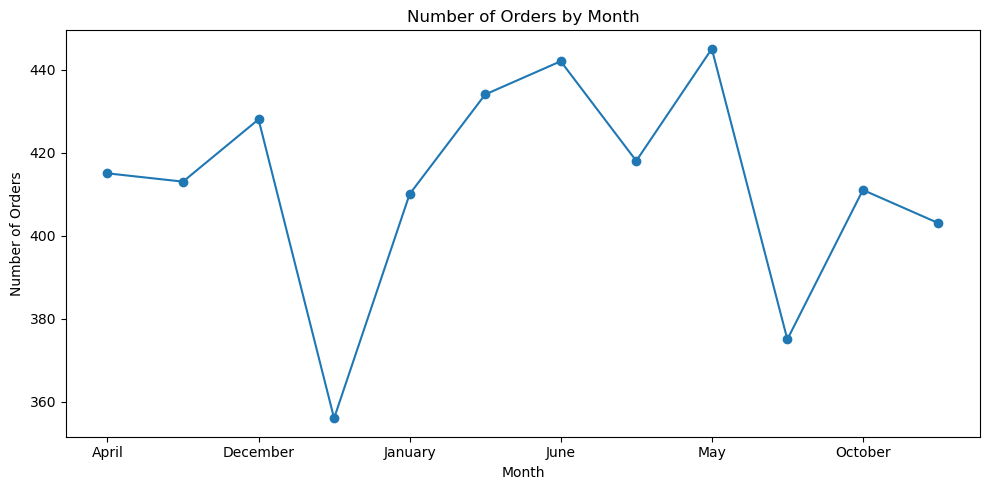

In [63]:
monthly_order_count = clean_orders.groupby(
    "Month"
).size()

monthly_order_count.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Number of Orders by Month")
plt.xlabel("Month")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

### Digging Deeper: Business Insights
1. Find the total sales for each Item inside each Branch. Which Branch and Item pair makes the most money?

In [64]:
branch_item_sales = (
    clean_orders
    .groupby(["Branch", "Item"])["Total_NGN"]
    .sum()
    .sort_values(ascending=False)
)

print(branch_item_sales)

# Find the Branch and Item combination making the most money
top_branch_item = branch_item_sales.idxmax()
top_branch_item_sales = branch_item_sales.max()

print(
    "\nHighest-revenue Branch and Item combination:",
    top_branch_item
)

print(
    f"Total sales: ₦{top_branch_item_sales:,.2f}"
)

Branch             Item        
Lagos Yaba         Chicken Suya    1635900
Abuja Wuse         Chicken Suya    1324000
                   Beef Suya       1097250
Lagos Yaba         Ram Suya        1052700
                   Beef Suya        960500
                   Kilishi          943000
Kaduna Central     Beef Suya        918000
                   Chicken Suya     757800
Kano Sabon Gari    Ram Suya         737500
Abuja Wuse         Ram Suya         737000
Kaduna Central     Ram Suya         720000
Kano Sabon Gari    Beef Suya        709500
Ibadan Bodija      Chicken Suya     610200
Kano Sabon Gari    Chicken Suya     599400
Port Harcourt GRA  Beef Suya        555200
Kaduna Central     Kilishi          540000
Ibadan Bodija      Beef Suya        510000
Jos Terminus       Chicken Suya     509400
Lagos Yaba         Gizzard          491400
Abuja Wuse         Kilishi          490600
Jos Terminus       Beef Suya        483000
Port Harcourt GRA  Chicken Suya     477750
Kano Sabon Gari    Kil

2. Find the average `Total_NGN` for delivery orders and for other orders.

In [65]:
delivery_average_sales = clean_orders.groupby(
    "Is_Delivery"
)["Total_NGN"].mean()

print(delivery_average_sales)

Is_Delivery
0    4483.094233
1    4689.068100
Name: Total_NGN, dtype: float64


3. Which `Payment_Method` has the highest average `Total_NGN`?

In [66]:
payment_average_sales = (
    clean_orders
    .groupby("Payment_Method")["Total_NGN"]
    .mean()
    .sort_values(ascending=False)
)

print(payment_average_sales)

highest_average_payment = payment_average_sales.idxmax()

print(
    "\nPayment method with highest average order value:",
    highest_average_payment
)

Payment_Method
POS         4851.390059
Unknown     4703.289474
Cash        4442.454308
Transfer    4420.902123
Name: Total_NGN, dtype: float64

Payment method with highest average order value: POS


4. Count how many orders have a `Rating` of 5 and how many have a `Rating` of 1.

In [67]:
rating_5_count = (clean_orders["Rating"] == 5).sum()
rating_1_count = (clean_orders["Rating"] == 1).sum()

print("Number of 5-star ratings:", rating_5_count)
print("Number of 1-star ratings:", rating_1_count)

Number of 5-star ratings: 1401
Number of 1-star ratings: 0


5. Find the average `Rating` for each Item. Which Item do customers like most?

In [68]:
item_average_rating = (
    clean_orders
    .groupby("Item")["Rating"]
    .mean()
    .sort_values(ascending=False)
)

print(item_average_rating)

most_liked_item = item_average_rating.idxmax()

print(
    "\nItem customers like most:",
    most_liked_item
)

Item
Chicken Suya    4.075598
Ram Suya        4.069324
Soft Drink      4.045198
Beef Suya       4.027007
Gizzard         4.018182
Kilishi         4.004532
Name: Rating, dtype: float64

Item customers like most: Chicken Suya


## Week 7: SQL for Data Science

Run in SQLite. Import `suya_orders.csv` as `orders` and `branches.csv` as `branches`.

### Monday: SELECT, WHERE, ORDER BY
1. Show the first 10 rows of `orders`.

In [78]:
# !pip install duckdb

In [79]:
import duckdb

In [80]:
duckdb.sql("""
    SELECT *
    FROM orders
    LIMIT 10;
""")

┌──────────┬────────────┬───────────────────┬──────────────┬──────────┬────────────────┬───────────┬────────────────┬──────────────┬────────┬─────────────┐
│ Order_ID │    Date    │      Branch       │     Item     │ Quantity │ Unit_Price_NGN │ Total_NGN │ Payment_Method │ Customer_Age │ Rating │ Is_Delivery │
│ varchar  │  varchar   │      varchar      │   varchar    │  int64   │     int64      │   int64   │    varchar     │    double    │ double │   varchar   │
├──────────┼────────────┼───────────────────┼──────────────┼──────────┼────────────────┼───────────┼────────────────┼──────────────┼────────┼─────────────┤
│ SP101081 │ 2025-08-03 │ Port Harcourt GRA │ Ram Suya     │        1 │           2700 │      2700 │ Cash           │         27.0 │    4.0 │ No          │
│ SP102241 │ 2025-03-14 │ Lagos Yaba        │ Chicken Suya │        6 │           2050 │     12300 │ Cash           │         41.0 │    5.0 │ No          │
│ SP102723 │ 2025-11-11 │ Enugu Ogui        │ Beef Suya    │    

2. Show only `Branch`, `Item` and `Total_NGN`.

In [81]:
duckdb.sql("""
    SELECT Branch, Item, Total_NGN
    FROM orders;
""")

┌───────────────────┬──────────────┬───────────┐
│      Branch       │     Item     │ Total_NGN │
│      varchar      │   varchar    │   int64   │
├───────────────────┼──────────────┼───────────┤
│ Port Harcourt GRA │ Ram Suya     │      2700 │
│ Lagos Yaba        │ Chicken Suya │     12300 │
│ Enugu Ogui        │ Beef Suya    │      7500 │
│ Enugu Ogui        │ Kilishi      │      2000 │
│ Kano Sabon Gari   │ Beef Suya    │      4500 │
│ Abuja Wuse        │ Chicken Suya │      2000 │
│ Kaduna Central    │ Beef Suya    │      1500 │
│ Lagos Yaba        │ Beef Suya    │      3400 │
│ Kano Sabon Gari   │ Beef Suya    │      3000 │
│ Jos Terminus      │ Kilishi      │      4000 │
│     ·             │    ·         │        ·  │
│     ·             │    ·         │        ·  │
│     ·             │    ·         │        ·  │
│ Abuja Wuse        │ Beef Suya    │      3300 │
│ Abuja Wuse        │ Chicken Suya │      6000 │
│ Ibadan Bodija     │ Gizzard      │      2400 │
│ Lagos Yaba        

3. Show only the orders from "Kaduna Central".

In [82]:
duckdb.sql("""
    SELECT *
    FROM orders
    WHERE Branch = 'Kaduna Central';
""")

┌──────────┬────────────┬────────────────┬──────────────┬──────────┬────────────────┬───────────┬────────────────┬──────────────┬────────┬─────────────┐
│ Order_ID │    Date    │     Branch     │     Item     │ Quantity │ Unit_Price_NGN │ Total_NGN │ Payment_Method │ Customer_Age │ Rating │ Is_Delivery │
│ varchar  │  varchar   │    varchar     │   varchar    │  int64   │     int64      │   int64   │    varchar     │    double    │ double │   varchar   │
├──────────┼────────────┼────────────────┼──────────────┼──────────┼────────────────┼───────────┼────────────────┼──────────────┼────────┼─────────────┤
│ SP102778 │ 2025-10-08 │ Kaduna Central │ Beef Suya    │        1 │           1500 │      1500 │ Cash           │         31.0 │    5.0 │ No          │
│ SP102146 │ 2025-09-17 │ Kaduna Central │ Chicken Suya │        1 │           1800 │      1800 │ Transfer       │         35.0 │    4.0 │ No          │
│ SP102643 │ 2025-09-13 │ Kaduna Central │ Ram Suya     │        2 │           250

4. Show the 5 biggest orders, from highest to lowest `Total_NGN`.

In [83]:
duckdb.sql("""
    SELECT *
    FROM orders
    ORDER BY Total_NGN DESC
    LIMIT 5;
""")

┌──────────┬────────────┬─────────────────┬──────────────┬──────────┬────────────────┬───────────┬────────────────┬──────────────┬────────┬─────────────┐
│ Order_ID │    Date    │     Branch      │     Item     │ Quantity │ Unit_Price_NGN │ Total_NGN │ Payment_Method │ Customer_Age │ Rating │ Is_Delivery │
│ varchar  │  varchar   │     varchar     │   varchar    │  int64   │     int64      │   int64   │    varchar     │    double    │ double │   varchar   │
├──────────┼────────────┼─────────────────┼──────────────┼──────────┼────────────────┼───────────┼────────────────┼──────────────┼────────┼─────────────┤
│ SP100391 │ 2025-04-07 │ Kano Sabon Gari │ Ram Suya     │      109 │           2500 │    272500 │ POS            │         17.0 │    3.0 │ No          │
│ SP104617 │ 2025-11-07 │ Lagos Yaba      │ Ram Suya     │       87 │           2900 │    252300 │ POS            │         20.0 │    4.0 │ Yes         │
│ SP101707 │ 2025-06-13 │ Lagos Yaba      │ Kilishi      │       98 │       

### Wednesday: GROUP BY, Aggregate Functions, JOINS
1. Count how many orders each Branch has.

In [84]:
duckdb.sql("""
    SELECT
    Branch,
    COUNT(*) AS order_count
    FROM orders
    GROUP BY Branch;
""")

┌───────────────────┬─────────────┐
│      Branch       │ order_count │
│      varchar      │    int64    │
├───────────────────┼─────────────┤
│ Port Harcourt GRA │         507 │
│ Enugu Ogui        │         416 │
│ Lagos Yaba        │         915 │
│ Ibadan Bodija     │         444 │
│ Kaduna Central    │         801 │
│ Kano Sabon Gari   │         679 │
│ Abuja Wuse        │         835 │
│ Jos Terminus      │         403 │
└───────────────────┴─────────────┘

2. Find the total `Total_NGN` for each Branch, highest first.

In [86]:
duckdb.sql("""
    SELECT
    Branch,
    SUM(Total_NGN) AS total_sales
    FROM orders
    GROUP BY Branch
    ORDER BY total_sales DESC;
""")

┌───────────────────┬─────────────┐
│      Branch       │ total_sales │
│      varchar      │   int128    │
├───────────────────┼─────────────┤
│ Lagos Yaba        │     5204600 │
│ Abuja Wuse        │     4010050 │
│ Kaduna Central    │     3281900 │
│ Kano Sabon Gari   │     2873100 │
│ Port Harcourt GRA │     2039050 │
│ Ibadan Bodija     │     1875900 │
│ Jos Terminus      │     1759000 │
│ Enugu Ogui        │     1647200 │
└───────────────────┴─────────────┘

3. Find the average `Rating` for each Item.

In [88]:
duckdb.sql("""
    SELECT
    Item,
    AVG(Rating) AS average_rating
    FROM orders
    GROUP BY Item;
""")

┌──────────────┬───────────────────┐
│     Item     │  average_rating   │
│   varchar    │      double       │
├──────────────┼───────────────────┤
│ Chicken Suya │ 4.075685903500473 │
│ Gizzard      │ 4.018083182640145 │
│ Beef Suya    │ 4.026831036983321 │
│ Kilishi      │ 4.004470938897168 │
│ Ram Suya     │  4.07032590051458 │
│ Soft Drink   │ 4.052631578947368 │
└──────────────┴───────────────────┘

4. Use a `JOIN` to show each order with its `Zone` from the `branches` table.

In [97]:
branches = pd.read_csv('data/branches.csv')

In [98]:
duckdb.sql("""
    SELECT
    orders.Order_ID,
    orders.Date,
    orders.Branch,
    orders.Item,
    orders.Total_NGN,
    branches.Zone
    FROM orders
    JOIN branches
    ON orders.Branch = branches.Branch;
""")

┌──────────┬────────────┬───────────────────┬──────────────┬───────────┬───────────────┐
│ Order_ID │    Date    │      Branch       │     Item     │ Total_NGN │     Zone      │
│ varchar  │  varchar   │      varchar      │   varchar    │   int64   │    varchar    │
├──────────┼────────────┼───────────────────┼──────────────┼───────────┼───────────────┤
│ SP101081 │ 2025-08-03 │ Port Harcourt GRA │ Ram Suya     │      2700 │ South South   │
│ SP102241 │ 2025-03-14 │ Lagos Yaba        │ Chicken Suya │     12300 │ South West    │
│ SP102723 │ 2025-11-11 │ Enugu Ogui        │ Beef Suya    │      7500 │ South East    │
│ SP101028 │ 2025-03-09 │ Enugu Ogui        │ Kilishi      │      2000 │ South East    │
│ SP100619 │ 2025-09-07 │ Kano Sabon Gari   │ Beef Suya    │      4500 │ North West    │
│ SP100191 │ 2025-04-26 │ Abuja Wuse        │ Chicken Suya │      2000 │ North Central │
│ SP102778 │ 2025-10-08 │ Kaduna Central    │ Beef Suya    │      1500 │ North West    │
│ SP103280 │ 2025-01-

5. Use a `JOIN` and `GROUP BY` to find total sales for each `Zone`.

In [99]:
duckdb.sql("""
    SELECT
    branches.Zone,
    SUM(orders.Total_NGN) AS total_sales
    FROM orders
    JOIN branches
    ON orders.Branch = branches.Branch
    GROUP BY branches.Zone
    ORDER BY total_sales DESC;
""")

┌───────────────┬─────────────┐
│     Zone      │ total_sales │
│    varchar    │   int128    │
├───────────────┼─────────────┤
│ South West    │     7080500 │
│ North West    │     6155000 │
│ North Central │     5769050 │
│ South South   │     2039050 │
│ South East    │     1647200 │
└───────────────┴─────────────┘

## Week 8: Advanced SQL and Cloud

1. **Subquery:** show all orders where `Total_NGN` is above the average `Total_NGN`.

In [100]:
duckdb.sql("""
    SELECT *
    FROM orders
    WHERE Total_NGN > (
    SELECT AVG(Total_NGN)
    FROM orders
);
""")


┌──────────┬────────────┬───────────────────┬──────────────┬──────────┬────────────────┬───────────┬────────────────┬──────────────┬────────┬─────────────┐
│ Order_ID │    Date    │      Branch       │     Item     │ Quantity │ Unit_Price_NGN │ Total_NGN │ Payment_Method │ Customer_Age │ Rating │ Is_Delivery │
│ varchar  │  varchar   │      varchar      │   varchar    │  int64   │     int64      │   int64   │    varchar     │    double    │ double │   varchar   │
├──────────┼────────────┼───────────────────┼──────────────┼──────────┼────────────────┼───────────┼────────────────┼──────────────┼────────┼─────────────┤
│ SP102241 │ 2025-03-14 │ Lagos Yaba        │ Chicken Suya │        6 │           2050 │     12300 │ Cash           │         41.0 │    5.0 │ No          │
│ SP102723 │ 2025-11-11 │ Enugu Ogui        │ Beef Suya    │        5 │           1500 │      7500 │ Cash           │         31.0 │    5.0 │ No          │
│ SP102643 │ 2025-09-13 │ Kaduna Central    │ Ram Suya     │    

2. **CASE:** add a column that says "Big" if `Total_NGN` is 8,000 or more, otherwise "Normal".

In [101]:
duckdb.sql("""
    SELECT
    Order_ID,
    Total_NGN,
    CASE
        WHEN Total_NGN >= 8000 THEN 'Big'
        ELSE 'Normal'
    END AS Order_Size
    FROM orders;
""")

┌──────────┬───────────┬────────────┐
│ Order_ID │ Total_NGN │ Order_Size │
│ varchar  │   int64   │  varchar   │
├──────────┼───────────┼────────────┤
│ SP101081 │      2700 │ Normal     │
│ SP102241 │     12300 │ Big        │
│ SP102723 │      7500 │ Normal     │
│ SP101028 │      2000 │ Normal     │
│ SP100619 │      4500 │ Normal     │
│ SP100191 │      2000 │ Normal     │
│ SP102778 │      1500 │ Normal     │
│ SP103280 │      3400 │ Normal     │
│ SP100602 │      3000 │ Normal     │
│ SP100289 │      4000 │ Normal     │
│    ·     │        ·  │   ·        │
│    ·     │        ·  │   ·        │
│    ·     │        ·  │   ·        │
│ SP103832 │      3300 │ Normal     │
│ SP102289 │      6000 │ Normal     │
│ SP103834 │      2400 │ Normal     │
│ SP104532 │      4100 │ Normal     │
│ SP104673 │      2500 │ Normal     │
│ SP101149 │      6000 │ Normal     │
│ SP101787 │      1000 │ Normal     │
│ SP100501 │      5400 │ Normal     │
│ SP104444 │      8200 │ Big        │
│ SP100382 │

3. **View:** create a view with the total sales for each Branch, then select from it.

In [102]:
duckdb.sql("""
    CREATE VIEW branch_sales AS
SELECT
    Branch,
    SUM(Total_NGN) AS total_sales
FROM orders
GROUP BY Branch;
""")

In [103]:
duckdb.sql("""
    SELECT *
    FROM branch_sales;
""")

┌───────────────────┬─────────────┐
│      Branch       │ total_sales │
│      varchar      │   int128    │
├───────────────────┼─────────────┤
│ Lagos Yaba        │     5204600 │
│ Ibadan Bodija     │     1875900 │
│ Port Harcourt GRA │     2039050 │
│ Enugu Ogui        │     1647200 │
│ Kaduna Central    │     3281900 │
│ Kano Sabon Gari   │     2873100 │
│ Abuja Wuse        │     4010050 │
│ Jos Terminus      │     1759000 │
└───────────────────┴─────────────┘

### Module Project 2
Upload `suya_orders.csv` to BigQuery. Find the total sales for each Branch.


## Week 9: Statistics

### Monday: Descriptive Statistics, Probability
1. Find the mean, median and mode of `Total_NGN`.

In [106]:
sales_mean = clean_orders["Total_NGN"].mean()
sales_median = clean_orders["Total_NGN"].median()
sales_mode = clean_orders["Total_NGN"].mode()

print("Mean:", sales_mean)
print("Median:", sales_median)
print("Mode:")
print(sales_mode)

Mean: 4541.141414141414
Median: 3300.0
Mode:
0    1500
Name: Total_NGN, dtype: int64


2. Find the standard deviation of `Customer_Age`.

In [108]:
age_standard_deviation = clean_orders["Customer_Age"].std()

print(
    "Standard deviation of Customer_Age:",
    age_standard_deviation
)

Standard deviation of Customer_Age: 7.592498953515733


3. Find the probability that a random order is a delivery.

In [107]:
delivery_probability = (
    clean_orders["Is_Delivery"] == 1
).mean()

print(
    "Probability of delivery:",
    delivery_probability
)

print(
    "Percentage of orders that are deliveries:",
    delivery_probability * 100,
    "%"
)

Probability of delivery: 0.2818181818181818
Percentage of orders that are deliveries: 28.18181818181818 %


### Wednesday: Sampling, Distributions, Confidence Intervals
1. Take a random sample of 100 orders. Compare its average `Total_NGN` to the average of all orders.

In [109]:
random_sample = clean_orders.sample(
    n=100,
    random_state=42
)

sample_average = random_sample["Total_NGN"].mean()
overall_average = clean_orders["Total_NGN"].mean()

print("Sample average:", sample_average)
print("Overall average:", overall_average)

Sample average: 4491.0
Overall average: 4541.141414141414


2. Draw a histogram of `Total_NGN`.

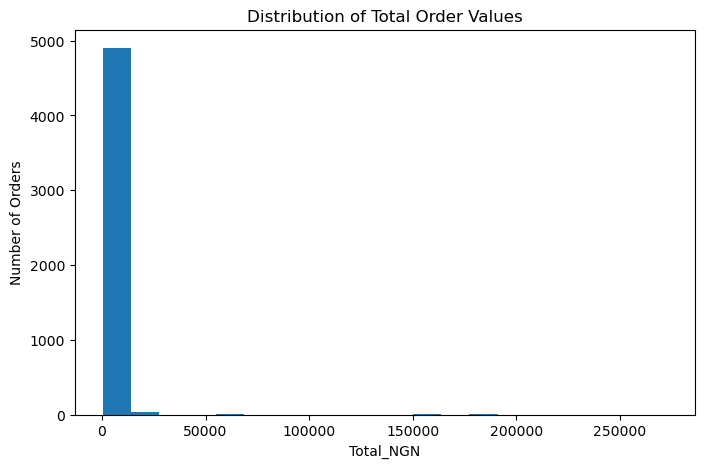

In [110]:
plt.figure(figsize=(8, 5))

plt.hist(
    clean_orders["Total_NGN"],
    bins=20
)

plt.title("Distribution of Total Order Values")
plt.xlabel("Total_NGN")
plt.ylabel("Number of Orders")

plt.show()

3. Find a 95% confidence interval for the average `Total_NGN` using a sample of 200 orders. Hint: average ± 1.96 × (standard deviation / √200).

In [111]:
# Take a random sample of 200 orders
confidence_sample = clean_orders.sample(
    n=200,
    random_state=42
)

# Calculate the sample mean
sample_mean = confidence_sample["Total_NGN"].mean()

# Calculate the sample standard deviation
sample_standard_deviation = confidence_sample["Total_NGN"].std()

# Calculate the standard error
standard_error = sample_standard_deviation / (200 ** 0.5)

# Calculate the margin of error
margin_of_error = 1.96 * standard_error

# Calculate the confidence interval
lower_limit = sample_mean - margin_of_error
upper_limit = sample_mean + margin_of_error

print("Sample mean:", sample_mean)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

print(
    f"95% Confidence Interval: "
    f"₦{lower_limit:,.2f} to ₦{upper_limit:,.2f}"
)

Sample mean: 4406.0
Lower limit: 3996.8045175883162
Upper limit: 4815.195482411684
95% Confidence Interval: ₦3,996.80 to ₦4,815.20
